In [1]:
import xarray as xr
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import sys
sys.path.append("/glade/work/smagahey/UCSB/codes/paper1_new/paper1/python_packages")
from myutils.composite_functions import select_events, var_composites

In [2]:
'''
Quiver and SST composites plotted together
Adjusted for La Nina types
12/2/24
Shay Magahey UCSB
'''

'\nQuiver and SST composites plotted together\nAdjusted for La Nina types\n12/2/24\nShay Magahey UCSB\n'

In [3]:
# sam suggested adding SST data? Composited SST changes?
# maybe do that in a new file

In [4]:
def plot_sst_quiver_composites(lon,lat,sstdata,regbox,n34,cmap,vmin,vmax,plttitle,cbticks,cblabel): #,figname):
    """
    Preliminary plots to show mean state changes in future relative to PI and PD
    data= data to plot, 2D (array) # ensst_arr
    regbox: region to plot (array)
    cmap=colormap (str)
    vmin,vmax: range for data (int)
    cblabel: colorbar label (str)
    cbticks: colorbar ticks (array)
    plttitle: plot title (str)
    figname: name.png (str)
    returns figure
    """
    
    fig = plt.figure(figsize=(10, 5))
    ax = fig.add_subplot(1,1,1,projection=ccrs.PlateCarree(central_longitude=180))
    #ax = plt.axes(projection=ccrs.PlateCarree())
    proj = ccrs.PlateCarree(central_longitude=180)
    n=3 
    
    #[::n,::n]
    #LON,LAT=np.meshgrid(lon,lat)
    im=ax.pcolormesh(lon,lat,sstdata,transform = ccrs.PlateCarree(),cmap=cmap,vmin=vmin,vmax=vmax)

    #plt.plot([n34[2], n34[3]],[n34[0], n34[0]], color='black',transform=ccrs.PlateCarree())
    #plt.plot([n34[2], n34[3]],[n34[1], n34[1]], color='black',transform=ccrs.PlateCarree())
    #plt.plot([n34[2], n34[2]],[n34[0], n34[1]], color='black',transform=ccrs.PlateCarree())
    #plt.plot([n34[3], n34[3]],[n34[0], n34[1]], color='black',transform=ccrs.PlateCarree())
    
    ax.set_extent([120, 280, regbox[0], regbox[1]], crs=ccrs.PlateCarree())
    
    #plt.xlim(120,280)
    #plt.ylim(regbox[0],regbox[1])
    plt.title(plttitle,fontsize=20)
    cbar1 = plt.colorbar(im,label=cblabel, orientation="horizontal",extend = 'both',ax=ax,drawedges=False, shrink = 0.7)
    cbar1.set_ticks(cbticks)
    #gl=ax.gridlines(crs=ccrs.PlateCarree(central_longitude=180), draw_labels=True,linewidth=.5, color='gray', alpha=0.5, linestyle='--')
    ax.coastlines()
    #gl.top_labels   = False
    #gl.right_labels = False
    #plt.savefig(figname)
    return

In [5]:
# need size of fb term to be good
# I think you can use this as is, just input fb with pacific-wide values

In [6]:
timesfut=["2070-01","2099-12"]
timespi=["1850-01","1879-12"]
tipast=["1850-01","2015-01"]
ep=[-5,5,210,270] #Nino3
n34=[-5,5,190,240] # nino3.4?
n4=[-5,5,160,210]
pac=[-5,5,120,280]
regbox=[-40,40,90,300]

In [7]:
yrsfut=np.array(['2070','2071','2072','2073','2074','2075','2076','2077','2078','2079','2080','2081','2082','2083','2084','2085','2086','2087','2088','2089','2090','2091','2092','2093','2094','2095','2096','2097','2098','2099'])
yrshist=np.array(['1850','1851','1852','1853','1854','1855','1856','1857','1858','1859','1860','1861','1862','1863','1864','1865','1866','1867','1868','1869','1870','1871','1872','1873','1874','1875','1876','1877','1878','1879'])
yrshist=xr.DataArray(yrshist,dims='time')
yrsfut=xr.DataArray(yrsfut,dims='time')

In [8]:
ds_sst=xr.open_dataset("/glade/work/smagahey/UCSB/codes/generated_files/tos_1850_2100_E3SMv1LE.nc")


In [9]:

tos=ds_sst['tos']
lon=ds_sst['lon']
lat=ds_sst['lat']
tos=tos-tos.mean('member')
# isolate for upper levels- lev 5 to 55

tospi=tos.sel(lat=slice(regbox[0],regbox[1]),lon=slice(regbox[2],regbox[3]),time=slice(timespi[0],timespi[1]))
tosfut=tos.sel(lat=slice(regbox[0],regbox[1]),lon=slice(regbox[2],regbox[3]),time=slice(timesfut[0],timesfut[1]))


In [10]:
# composite of anomalies, or composite THEN anomalies?

Calculate anomalies, then composites

In [11]:
# anomalies then composite:


In [12]:
tospi_anom=tospi.groupby('time.month')-tospi.groupby('time.month').mean()
tosfut_anom=tosfut.groupby('time.month')-tosfut.groupby('time.month').mean()

In [13]:
enyrs_h,lnyrs_h=select_events(tospi,n34,regbox,1850,1880,timespi)
enyrs_f,lnyrs_f=select_events(tosfut,n34,regbox,2070,2100,timesfut)

In [14]:
entos_pi,lntos_pi=var_composites(tospi_anom,yrshist,enyrs_h,lnyrs_h,24)
entos_fut,lntos_fut=var_composites(tosfut_anom,yrsfut,enyrs_f,lnyrs_f,24)

In [15]:
m1=-7
m2=-5

In [16]:
#piU_en.time

Calculate composites, then anomalies (is this possible? or reasonable?)

In [17]:
lntos_pi=lntos_pi.sel(time=slice(m1,m2)).mean('time').mean('member')
lntos_fut=lntos_fut.sel(time=slice(m1,m2)).mean('time').mean('member')

In [18]:
entos_pi=entos_pi.sel(time=slice(m1,m2)).mean('time').mean('member')
entos_fut=entos_fut.sel(time=slice(m1,m2)).mean('time').mean('member')

Plot PI composites

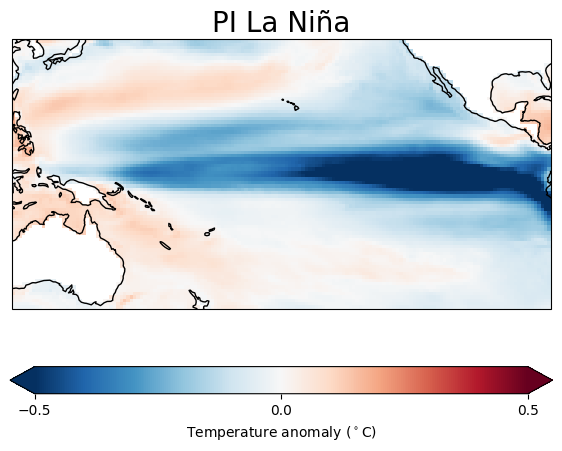

In [23]:
plot_sst_quiver_composites(lntos_pi.lon,lntos_pi.lat,lntos_pi,regbox,n34,'RdBu_r',-.5,.5,'PI La Niña',[-.5,0,.5],r'Temperature anomaly ($^\circ$C)') #'histSON_LN_precEN.png')



In [20]:
tosdiff=lntos_fut - lntos_pi

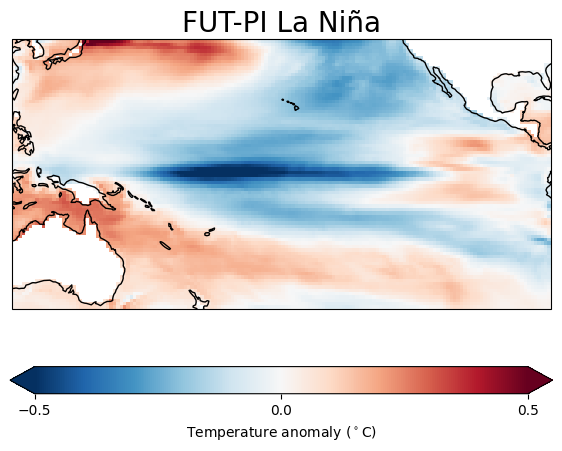

In [24]:
plot_sst_quiver_composites(lntos_pi.lon,lntos_pi.lat, tosdiff,regbox,n34,'RdBu_r',-.5,.5,'FUT-PI La Niña',[-.5,0,.5],r'Temperature anomaly ($^\circ$C)') #'histSON_LN_precEN.png')



In [22]:
plot_sst_quiver_composites(LON,LAT,Udev_piEN,Vdev_piEN,entos_pi,regbox,n34,15,'RdBu_r',-3,3,'El Nino PI DJF SSTA and wind anom',[-3,0,3],'Temperature anomaly deg C') #'histSON_LN_precLN.png')


NameError: name 'LON' is not defined

In [ ]:
plot_sst_quiver_composites(LON,LAT,Udev_futEN,Vdev_futEN,entos_fut,regbox,n34,15,'RdBu_r',-3,3,'El Nino FUT DJF SSTA and wind anom',[-3,0,3],'Temperature anomaly deg C') #'futSON_LN_precLN.png')


In [ ]:
#plot_sst_quiver_composites(LON,LAT,Udev_pi_noENSO,Vdev_pi_noENSO,sstdev_pi_noENSO,regbox,n34,20,'RdBu_r',-3,3,'Historical MAM-1 SSTA and wind anom (w no preceding ENSO)',[-2,0,2],'Temperature anomaly deg C') #,'histSON_LN_noENSO.png')


In [ ]:
#plot_sst_quiver_composites(LON,LAT,Udev_fut_noENSO,Vdev_fut_noENSO,sstdev_fut_noENSO,regbox,n34,20,'RdBu_r',-3,3,'Future MAM-1 SSTA and wind anom (w no preceding ENSO)',[-2,0,2],'Temperature anomaly deg C')#'futSON_LN_noENSO.png')


In [ ]:
# change in temperature, wind anomalies?

In [ ]:
changeU_EN = Udev_futEN - Udev_piEN
changeV_EN = Vdev_futEN - Vdev_piEN
changeU_LN = Udev_futLN - Udev_piLN
changeV_LN = Vdev_futLN - Vdev_piLN
sst_change_EN = entos_fut- entos_pi #
sst_change_LN = lntos_fut- lntos_pi

In [ ]:
#plot_sst_quiver_composites(LON,LAT,changeU_EN,changeV_EN,sst_change_EN,regbox,10,'seismic',-2,2,'Change in JJA El Nino surface wind anomaly and SSTA',[-2,0,2],'Temperature anomaly deg C')


In [ ]:
plot_sst_quiver_composites(LON,LAT,changeU_LN,changeV_LN,sst_change_LN,regbox,n34,10,'RdBu_r',-1,1,'Change in DJF La Nina surface wind anomaly and SSTA',[-1,0,1],'Temperature anomaly deg C')



In [ ]:
plot_sst_quiver_composites(LON,LAT,changeU_EN,changeV_EN,sst_change_EN,regbox,n34,10,'RdBu_r',-1,1,'Change in DJF El Nino surface wind anomaly and SSTA',[-1,0,1],'Temperature anomaly deg C')



Apply bootstrap so only plot significant wind changes

In [ ]:
def my_statistic(sample1, sample2, axis=0):
    mean1 = np.mean(sample1, axis=axis)
    mean2 = np.mean(sample2, axis=axis)
    return mean1 - mean2

In [ ]:
import scipy.stats as stats

In [ ]:
m1=23
m2=26

In [ ]:
Udev_piEN=piU_en.isel(time=slice(m1,m2)).mean('time')
Vdev_piEN=piV_en.isel(time=slice(m1,m2)).mean('time')
Udev_piLN=piU_ln.isel(time=slice(m1,m2)).mean('time')
Vdev_piLN=piV_ln.isel(time=slice(m1,m2)).mean('time')

In [ ]:
Udev_futEN=futU_en.isel(time=slice(m1,m2)).mean('time')
Vdev_futEN=futV_en.isel(time=slice(m1,m2)).mean('time')
Udev_futLN=futU_ln.isel(time=slice(m1,m2)).mean('time')
Vdev_futLN=futV_ln.isel(time=slice(m1,m2)).mean('time')

In [ ]:
lon,lat=np.meshgrid(Udev_piEN.lon,Udev_piEN.lat)

In [ ]:
plot_sig_quiver_composites(lon,lat,Udev_piEN,Vdev_piEN,sst_change_EN,regbox,25,'seismic',-2,2,"Surface WInd anomaly and SST difference FUT-PI, El Nino",[-2,0,2],'SSTA degC')





In [ ]:
plot_sig_quiver_composites(lon,lat,Udev_futEN,Vdev_futEN,sst_change_EN,regbox,25,'seismic',-2,2,"Surface WInd anomaly and SST difference FUT-PI, La Nina",[-2,0,2],'SSTA degC')


